# Full explanations vs. shortened explanation history

Similarity + QED on the 20 random PubChem molecules (Claude Opus 4.5). Compares the full-explanation mode with the shortened-history modes:

- **last_k**: explanations of the last k valid molecules stay in the prompt (at most k explanations).
- **best_worst_k**: explanations of the k best and k worst valid molecules (combined score) stay in the prompt (at most 2k explanations).

So `last_k` and `best_worst_(k/2)` have the same explanation budget and are plotted next to each other. All modes found in the results folder are used, so runs that finish later are picked up by re-running the notebook.

Aggregation: every run (one result file) gets its own metric first. Runs of the same molecule are then averaged (full explanations has three runs per molecule), and mean and 95% CI (t-distribution) are computed across molecules.

In [11]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

np.random.seed(42)

RESULTS_DIR = Path('../../data/results/similarity_qed_pubchem')
MODEL_PREFIX = 'claude-opus-4.5'
MAX_ORACLE_CALLS = 50

# True: only compare on molecules that have results in every mode. Useful while some modes are still
# running (otherwise the modes are averaged over different molecule subsets).
RESTRICT_TO_COMMON_MOLECULES = False

FULL_COLOR = '#2E86AB'
NONE_COLOR = '#ffcc00'
LAST_COLORS = ['#00a69d', '#00756f', '#004a46']  # lighter -> darker with growing k
BEST_WORST_COLORS = ['#f58220', '#c4620d', '#8a420a']

plt.rcParams.update({
    'font.size': 12, 'font.family': 'serif', 'axes.labelsize': 13, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'axes.linewidth': 1.2, 'grid.linewidth': 0.6, 'lines.linewidth': 2.5,
})

## Loading data

In [12]:
def discover_modes() -> list[dict]:
    '''No-explanation mode, shortened-history modes found in the results folder (ordered by budget), then the full mode.

    budget = maximum number of explanations in the prompt: k for last_k, 2k for best_worst_k.
    '''
    pattern = re.compile(re.escape(MODEL_PREFIX) + r'_(last|best_worst)([0-9]+)_xai(?:_None)?')
    found = []
    for folder in RESULTS_DIR.iterdir():
        match = pattern.fullmatch(folder.name)
        if match and folder.is_dir():
            family = 'last_k' if match.group(1) == 'last' else 'best_worst_k'
            k = int(match.group(2))
            found.append({'family': family, 'k': k, 'budget': k if family == 'last_k' else 2 * k, 'folder': folder.name})
    found.sort(key=lambda m: (m['budget'], m['family'] != 'last_k'))

    for family, palette in (('last_k', LAST_COLORS), ('best_worst_k', BEST_WORST_COLORS)):
        ks = sorted(m['k'] for m in found if m['family'] == family)
        for m in found:
            if m['family'] == family:
                m['color'] = palette[min(ks.index(m['k']), len(palette) - 1)]
                m['label'] = f"{'Last-k' if family == 'last_k' else 'Best/Worst-k'} (k={m['k']})"

    full = {'family': 'full', 'k': None, 'budget': np.inf, 'folder': f'{MODEL_PREFIX}_full_xai',
            'color': FULL_COLOR, 'label': 'Full explanations'}
    none = {'family': 'none', 'k': None, 'budget': 0, 'folder': f'{MODEL_PREFIX}_no_xai',
            'color': NONE_COLOR, 'label': 'No explanations'}
    return [none] + found + [full]


def load_runs(modes: list[dict]) -> tuple[pd.DataFrame, pd.DataFrame]:
    '''One row per run (result file) and one row per valid trace entry.'''
    runs, rows = [], []
    for mode in modes:
        for path in sorted((RESULTS_DIR / mode['folder']).glob('sim_qed_pubchem_mol*_conversation_*.json')):
            molecule = re.search(r'mol[0-9]+', path.name).group()
            trace = json.loads(path.read_text(encoding='utf-8')).get('trace', [])
            runs.append({'mode': mode['label'], 'molecule': molecule, 'run': path.stem})
            rows.extend({'run': path.stem, 'iteration': int(e['iteration']), 'score': float(e['score'])} for e in trace)
    return pd.DataFrame(runs), pd.DataFrame(rows)


all_modes = discover_modes()
runs_df, rows_df = load_runs(all_modes)
modes = [m for m in all_modes if m['label'] in set(runs_df['mode'])]  # drop modes without results

if RESTRICT_TO_COMMON_MOLECULES:
    common = set.intersection(*[set(g['molecule']) for _, g in runs_df.groupby('mode')])
    runs_df = runs_df[runs_df['molecule'].isin(common)]
    rows_df = rows_df[rows_df['run'].isin(runs_df['run'])]
    print(f'Restricted to {len(common)} molecules present in every mode')

coverage = runs_df.groupby('mode').agg(runs=('run', 'count'), molecules=('molecule', 'nunique')).reindex([m['label'] for m in modes])
display(coverage)
if coverage['molecules'].nunique() > 1:
    print('Warning: modes cover different numbers of molecules (runs still in progress?), so they are averaged over different subsets.')

,runs,molecules
mode,,
No explanations,60,20
Last-k (k=2),20,20
Best/Worst-k (k=1),20,20
Last-k (k=10),20,20
Best/Worst-k (k=5),20,20
Full explanations,60,20


---
## Top-1 AUC and best score per mode

Top-1 AUC: area under the best-so-far (combined score) curve over the first 50 oracle calls (trapezoidal rule, as in the PMO benchmark), normalised to [0, 1]. The best score is the highest combined score within the same 50 oracle calls.

In [13]:
def compute_auc_top1(group_df: pd.DataFrame, max_oracle_calls: int = 50) -> float:
    '''AUC of the best-so-far score vs. oracle calls for a single run.'''
    sorted_df = group_df.sort_values('iteration')

    best_score = 0.0
    best_at_call = {}
    for row in sorted_df.itertuples():
        if row.iteration > max_oracle_calls:
            break
        best_score = max(best_score, float(row.score))
        best_at_call[int(row.iteration)] = best_score

    if not best_at_call:
        return 0.0

    auc, prev_call, prev_best = 0.0, 0, 0.0
    for call in sorted(best_at_call):
        auc += (call - prev_call) * (best_at_call[call] + prev_best) / 2
        prev_call, prev_best = call, best_at_call[call]

    # Extend to max_oracle_calls with the last value, normalise to the average best-so-far score
    auc += (max_oracle_calls - prev_call) * prev_best
    return auc / max_oracle_calls


def mean_ci95(values) -> tuple[float, float]:
    '''Mean and 95% CI half-width (t-distribution); NaN half-width for fewer than two values.'''
    v = np.asarray(values, dtype=float)
    if len(v) == 0:
        return np.nan, np.nan
    if len(v) < 2:
        return float(v.mean()), np.nan
    return float(v.mean()), float(stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)))


# 1) one value per run
rows_by_run = {run: g for run, g in rows_df.groupby('run')}
run_records = []
for r in runs_df.itertuples():
    g = rows_by_run.get(r.run)
    g = g[g['iteration'] <= MAX_ORACLE_CALLS] if g is not None else None
    run_records.append({
        'mode': r.mode, 'molecule': r.molecule, 'run': r.run,
        'auc_top1': compute_auc_top1(g, MAX_ORACLE_CALLS) if g is not None else 0.0,
        'best_score': float(g['score'].max()) if g is not None and len(g) else 0.0,
    })
run_metrics = pd.DataFrame(run_records)

# 2) average the runs of each molecule, 3) mean and CI across molecules
molecule_metrics = run_metrics.groupby(['mode', 'molecule'], as_index=False)[['auc_top1', 'best_score']].mean()

summary_rows = []
for mode in modes:
    runs_mode = run_metrics[run_metrics['mode'] == mode['label']]
    mols = molecule_metrics[molecule_metrics['mode'] == mode['label']]
    auc_mean, auc_ci = mean_ci95(mols['auc_top1'])
    best_mean, best_ci = mean_ci95(mols['best_score'])
    summary_rows.append({
        'Mode': mode['label'], 'Runs': len(runs_mode), 'Molecules': len(mols),
        'AUC Top-1': auc_mean, 'AUC Top-1 95% CI (+/-)': auc_ci,
        'Best score': best_mean, 'Best score 95% CI (+/-)': best_ci,
    })
summary = pd.DataFrame(summary_rows).set_index('Mode')

print(f'Top-1 AUC and best combined score within {MAX_ORACLE_CALLS} oracle calls (mean +/- 95% CI across molecules)')
display(summary.round(3))

Top-1 AUC and best combined score within 50 oracle calls (mean +/- 95% CI across molecules)


,Runs,Molecules,AUC Top-1,AUC Top-1 95% CI (+/-),Best score,Best score 95% CI (+/-)
Mode,,,,,,
No explanations,60,20,0.756,0.028,0.784,0.028
Last-k (k=2),20,20,0.774,0.032,0.803,0.032
Best/Worst-k (k=1),20,20,0.778,0.031,0.813,0.028
Last-k (k=10),20,20,0.779,0.027,0.815,0.025
Best/Worst-k (k=5),20,20,0.779,0.029,0.809,0.030
Full explanations,60,20,0.780,0.031,0.816,0.031


---
## Top-1 AUC vs. explanation budget

Modes with the same maximum number of explanations in the prompt sit next to each other (`last_k` left, `best_worst_(k/2)` right). The no-explanation mode is on the far left, the groups follow ordered by budget, and the full-explanation mode (unbounded) is on the far right. Lines connect the same family from the no-explanation point to the full-explanation point. Error bars are 95% CIs across molecules.

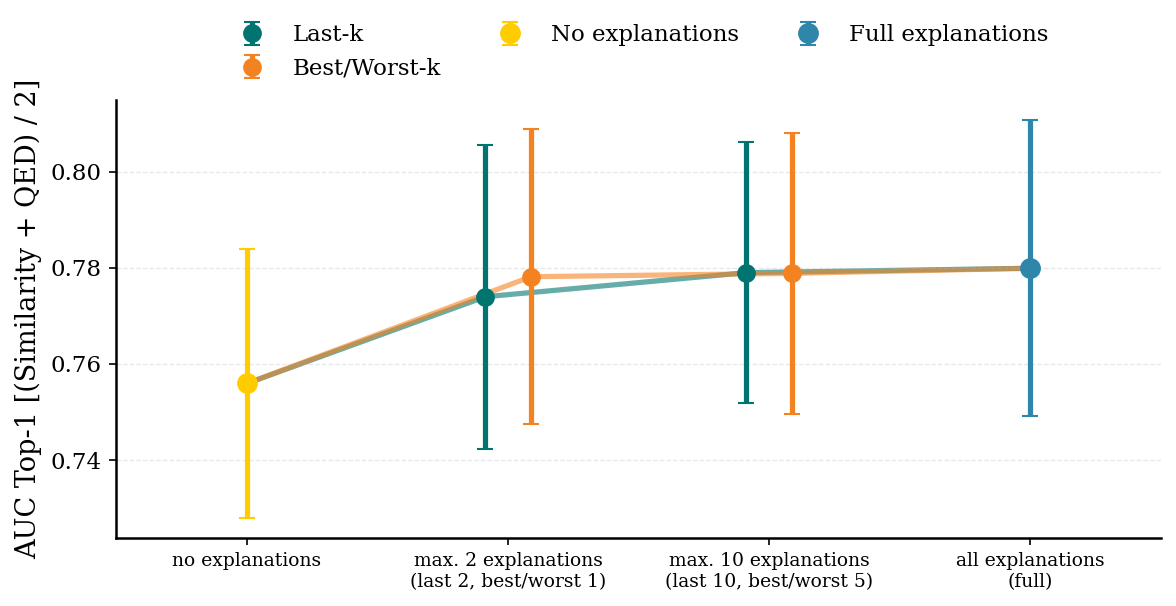

In [14]:
GROUP_SPACING = 1.6  # distance between budget groups
PAIR_OFFSET = 0.14   # half distance between last_k and best_worst_k inside a group

budgets = sorted({m['budget'] for m in modes if m['family'] not in ('full', 'none')})
none_x = 0.0
group_x = {b: (i + 1) * GROUP_SPACING for i, b in enumerate(budgets)}
full_x = (len(budgets) + 1) * GROUP_SPACING


def x_position(mode: dict) -> float:
    if mode['family'] == 'none':
        return none_x
    if mode['family'] == 'full':
        return full_x
    return group_x[mode['budget']] + (-PAIR_OFFSET if mode['family'] == 'last_k' else PAIR_OFFSET)


def point(mode: dict) -> tuple[float, float, float]:
    row = summary.loc[mode['label']]
    return x_position(mode), row['AUC Top-1'], row['AUC Top-1 95% CI (+/-)']


full_mode = next(m for m in modes if m['family'] == 'full')
none_mode = next((m for m in modes if m['family'] == 'none'), None)
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)

series = [('last_k', 'Last-k', LAST_COLORS[1]), ('best_worst_k', 'Best/Worst-k', BEST_WORST_COLORS[0])]
for family, label, color in series:
    members = [m for m in modes if m['family'] == family]
    if not members:
        continue
    # line runs from no explanations through the family to full explanations
    pts = ([point(none_mode)] if none_mode else []) + [point(m) for m in members] + [point(full_mode)]
    xs, ys, cis = zip(*pts)
    ax.plot(xs, ys, '-', color=color, alpha=0.6, zorder=1)
    xs_m, ys_m, cis_m = zip(*[point(m) for m in members])
    ax.errorbar(xs_m, ys_m, yerr=np.nan_to_num(cis_m), fmt='o', color=color, capsize=4, markersize=8, label=label, zorder=3)

if none_mode:
    nx, ny, nci = point(none_mode)
    ax.errorbar([nx], [ny], yerr=[np.nan_to_num(nci)], fmt='o', color=NONE_COLOR, capsize=4, markersize=9, label='No explanations', zorder=4)
fx, fy, fci = point(full_mode)
ax.errorbar([fx], [fy], yerr=[np.nan_to_num(fci)], fmt='o', color=FULL_COLOR, capsize=4, markersize=9, label='Full explanations', zorder=4)

tick_pos = ([none_x] if none_mode else []) + [group_x[b] for b in budgets] + [full_x]
tick_labels = ['no explanations'] if none_mode else []
for b in budgets:
    parts = [f"{'last' if m['family'] == 'last_k' else 'best/worst'} {m['k']}" for m in modes if m['budget'] == b]
    tick_labels.append(f'max. {int(b)} explanations\n(' + ', '.join(parts) + ')')
tick_labels.append('all explanations\n(full)')
ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_labels, fontsize=9)
ax.set_xlim(-0.8, full_x + 0.8)

ax.set_ylabel('AUC Top-1 [(Similarity + QED) / 2]')
ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
legend = ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)

plt.tight_layout()
plt.savefig('./figures/xai_history_modes_auc.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()

---
## Paired comparison per molecule

The molecules differ strongly in difficulty (spread of the AUC across molecules is much larger than the difference between modes), so the CIs above mostly reflect molecule difficulty. All modes were run on the same molecules, so the modes are compared **per molecule**: for every pair of modes the difference `B - A` of the top-1 AUC is computed for each molecule, then summarised (mean, 95% CI across molecules, number of molecules with a positive difference, sign test).

- Pairs are ordered along the explanation budget: no explanations < max. 2 < max. 10 < full. `stage` rows are the consecutive steps within one family (none -> k -> ... -> full); `same budget` compares `last_k` with `best_worst_(k/2)`; `other` is every remaining pair.
- No explanations and full explanations have three runs per molecule (numbered chronologically by the timestamp in the file name). Every comparison involving them is reported with each run individually (`run 1`, `run 2`, `run 3`; if both modes have three runs, run i is paired with run i) and with the mean of the three runs. The shortened modes have a single run per molecule.

In [15]:
from itertools import combinations

# number runs of the same molecule and mode chronologically (timestamp in the file name)
run_metrics['timestamp'] = run_metrics['run'].str.extract(r'_conversation_([0-9]+_[0-9]+)')[0]
run_metrics['rep_idx'] = run_metrics.sort_values('timestamp').groupby(['mode', 'molecule']).cumcount() + 1
n_reps = run_metrics.groupby('mode')['rep_idx'].max()

auc_by_run = run_metrics.pivot_table(index='molecule', columns=['mode', 'rep_idx'], values='auc_top1')


def auc_per_molecule(label: str, variant) -> pd.Series:
    '''AUC per molecule for a mode. variant: 'mean' (mean of the runs) or the run number (single-run modes ignore it).'''
    runs = auc_by_run[label].dropna(how='all')
    if variant == 'mean':
        return runs.mean(axis=1)
    return runs[variant] if variant in runs.columns else runs[1]


def paired_stats(diff: pd.Series) -> dict:
    diff = diff.dropna()
    n, pos, neg = len(diff), int((diff > 0).sum()), int((diff < 0).sum())
    mean, ci = mean_ci95(diff)
    p_sign = stats.binomtest(pos, pos + neg, 0.5).pvalue if pos + neg > 0 else np.nan
    return {'n': n, 'mean diff': mean, '95% CI (+/-)': ci, 'SD of diff': diff.std(ddof=1) if n > 1 else np.nan,
            'positive': f'{pos}/{n}', 'p (sign test)': p_sign}


stage_pairs = set()
for family in ('last_k', 'best_worst_k'):
    chain = [m for m in modes if m['family'] == 'none'] + [m for m in modes if m['family'] == family] + [m for m in modes if m['family'] == 'full']
    stage_pairs |= {(a['label'], b['label']) for a, b in zip(chain, chain[1:])}

comparison_rows = []
for a, b in combinations(modes, 2):  # `modes` is ordered by budget, so B has the larger budget
    if (a['label'], b['label']) in stage_pairs:
        kind = 'stage'
    elif a['budget'] == b['budget']:
        kind = 'same budget'
    else:
        kind = 'other'
    max_reps = max(n_reps[a['label']], n_reps[b['label']])
    variants = ['mean'] + list(range(1, max_reps + 1)) if max_reps > 1 else [1]
    for variant in variants:
        diff = auc_per_molecule(b['label'], variant) - auc_per_molecule(a['label'], variant)
        basis = 'single runs' if variant == 1 and max_reps == 1 else ('mean of runs' if variant == 'mean' else f'run {variant}')
        comparison_rows.append({'Kind': kind, 'Comparison (B - A)': f"{a['label']} -> {b['label']}", 'Basis': basis, **paired_stats(diff)})

kind_order = {'stage': 0, 'same budget': 1, 'other': 2}
comparisons = pd.DataFrame(comparison_rows)
comparisons['_k'] = comparisons['Kind'].map(kind_order)
comparisons = comparisons.sort_values('_k', kind='stable').drop(columns='_k').set_index(['Kind', 'Comparison (B - A)', 'Basis'])

print(f'Paired differences of the top-1 AUC per molecule (B - A), {MAX_ORACLE_CALLS} oracle calls')
display(comparisons.round({'mean diff': 4, '95% CI (+/-)': 4, 'SD of diff': 4, 'p (sign test)': 3}))

Paired differences of the top-1 AUC per molecule (B - A), 50 oracle calls


n  \
Kind        Comparison (B - A)                       Basis              
stage       No explanations -> Last-k (k=2)          mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            No explanations -> Best/Worst-k (k=1)    mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            Last-k (k=2) -> Last-k (k=10)            single runs   20   
            Best/Worst-k (k=1) -> Best/Worst-k (k=5) single runs   20   
            Last-k (k=10) -> Full explanations       mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            Best/Worst-k (k=5) -> Full explanations  mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
same budget Last-k (k=2) -> Best/Worst-k (k=1)       single runs   20   
            Last-k (k=10) -> Best/Worst-k (k=5)      single runs   20   
other       No explanations -> Last-k (k=10)         mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            No explanations -> Best/Worst-k (k=5)    mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            No explanations -> Full explanations     mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            Last-k (k=2) -> Best/Worst-k (k=5)       single runs   20   
            Last-k (k=2) -> Full explanations        mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   
            Best/Worst-k (k=1) -> Last-k (k=10)      single runs   20   
            Best/Worst-k (k=1) -> Full explanations  mean of runs  20   
                                                     run 1         20   
                                                     run 2         20   
                                                     run 3         20   

                                                                   mean diff  \
Kind        Comparison (B - A)                       Basis                     
stage       No explanations -> Last-k (k=2)          mean of runs     0.0180   
                                                     run 1            0.0129   
                                                     run 2            0.0265   
                                                     run 3            0.0147   
            No explanations -> Best/Worst-k (k=1)    mean of runs     0.0222   
                                                     run 1            0.0171   
                                                     run 2            0.0307   
                                                     run 3            0.0189   
            Last-k (k=2) -> Last-k (k=10)            si

### Per-molecule paths along the explanation budget

Every grey line is one molecule: its top-1 AUC with no explanations, with the shortened modes of one family, and with full explanations. For no explanations and full explanations the point is the mean of the three runs of that molecule; the shortened modes are single runs. The coloured line is the mean over molecules.

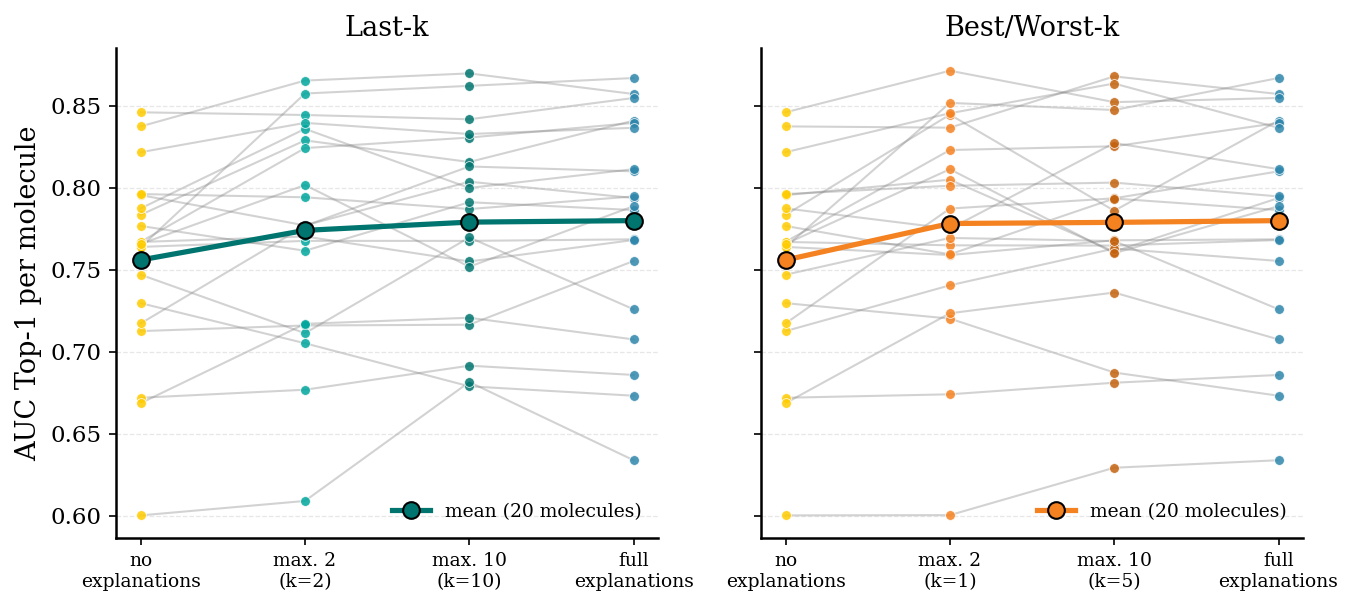

In [16]:
avg_auc = run_metrics.groupby(['mode', 'molecule'])['auc_top1'].mean().unstack(0)

panels = []
for family, title, line_color in (('last_k', 'Last-k', LAST_COLORS[1]), ('best_worst_k', 'Best/Worst-k', BEST_WORST_COLORS[0])):
    chain = [m for m in modes if m['family'] == 'none'] + [m for m in modes if m['family'] == family] + [m for m in modes if m['family'] == 'full']
    if any(m['family'] == family for m in chain):
        panels.append((title, line_color, chain))

fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 4.2), sharey=True, dpi=150, squeeze=False)
for ax, (title, line_color, chain) in zip(axes[0], panels):
    labels = [m['label'] for m in chain]
    data = avg_auc[labels].dropna()  # molecules with results in every mode of the chain
    x = np.arange(len(chain))
    for _, row in data.iterrows():
        ax.plot(x, row.values, '-', color='grey', alpha=0.35, linewidth=1, zorder=1)
    for xi, m in zip(x, chain):
        ax.scatter(np.full(len(data), xi), data[m['label']], color=m['color'], s=22, alpha=0.85, edgecolor='white', linewidth=0.4, zorder=3)
    ax.plot(x, data.mean().values, '-o', color=line_color, linewidth=2.5, markersize=8, markeredgecolor='black', zorder=4, label=f'mean ({len(data)} molecules)')

    def tick(m):
        if m['family'] == 'none':
            return 'no\nexplanations'
        if m['family'] == 'full':
            return 'full\nexplanations'
        return f"max. {int(m['budget'])}\n(k={m['k']})"

    ax.set_xticks(x)
    ax.set_xticklabels([tick(m) for m in chain], fontsize=9)
    ax.set_title(title, fontsize=13)
    ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(frameon=False, loc='lower right', fontsize=9)

axes[0][0].set_ylabel('AUC Top-1 per molecule')
plt.tight_layout()
plt.savefig('./figures/xai_history_modes_paired_molecules.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()

---
## Statistical tests for the headline claims

Both questions are answered **per molecule** (paired), because the molecules differ strongly in difficulty. For every molecule the AUC of one mode is compared with the AUC of another mode on the same molecule, and the 20 differences are tested.

1. **Do explanations help?** Every mode with explanations minus *no explanations*. Paired t-test, with the Wilcoxon signed-rank test as a check that does not assume normal differences. A small p-value means the gain is unlikely to be chance.
2. **Is a shortened history as good as the full history?** A non-significant difference does not show that two modes are equal, so this uses an *equivalence test* (TOST): the shortened mode counts as equivalent to full if the 90% CI of the difference lies inside +/- `EQUIV_MARGIN` AUC. A small p-value means equivalent within that margin.

p-values are corrected for multiple comparisons within each question (Holm).

In [18]:
from statsmodels.stats.multitest import multipletests

EQUIV_MARGIN = 0.02  # AUC difference regarded as practically irrelevant (about the size of the gain from explanations)

mol_auc = molecule_metrics.pivot(index='molecule', columns='mode', values='auc_top1')  # runs of a molecule already averaged
none_mode = next(m for m in modes if m['family'] == 'none')
full_mode = next(m for m in modes if m['family'] == 'full')
shortened = [m for m in modes if m['family'] not in ('none', 'full')]


def paired_diff(label_b: str, label_a: str) -> np.ndarray:
    '''Per-molecule AUC difference B - A, only molecules with results in both modes.'''
    pair = mol_auc[[label_b, label_a]].dropna()
    return (pair[label_b] - pair[label_a]).to_numpy()


# 1) do explanations help? (each explained mode - no explanations)
rows = []
for m in shortened + [full_mode]:
    x = paired_diff(m['label'], none_mode['label'])
    mean, ci = mean_ci95(x)
    rows.append({
        'Comparison': f"{m['label']} - {none_mode['label']}", 'Molecules': len(x),
        'Mean diff': mean, '95% CI low': mean - ci, '95% CI high': mean + ci,
        'Molecules improved': f'{int((x > 0).sum())}/{len(x)}',
        'p (paired t)': stats.ttest_1samp(x, 0).pvalue, 'p (Wilcoxon)': stats.wilcoxon(x).pvalue,
    })
help_df = pd.DataFrame(rows).set_index('Comparison')
help_df['p (paired t), Holm'] = multipletests(help_df['p (paired t)'], method='holm')[1]
help_df['p (Wilcoxon), Holm'] = multipletests(help_df['p (Wilcoxon)'], method='holm')[1]

print('1) Do explanations help? Per-molecule AUC difference (explained mode - no explanations)')
display(help_df.round(4))
worst_p = max(help_df['p (paired t), Holm'].max(), help_df['p (Wilcoxon), Holm'].max())
print(f"-> All {len(help_df)} modes with explanations score {help_df['Mean diff'].min():.3f} to {help_df['Mean diff'].max():.3f} AUC higher than no explanations; "
      f"largest corrected p-value over both tests = {worst_p:.3f} ({'all below 0.05' if worst_p < 0.05 else 'NOT all below 0.05'}).")

# 2) is a shortened history equivalent to full? (TOST, shortened - full)
rows = []
for m in shortened:
    x = paired_diff(m['label'], full_mode['label'])
    n, mean = len(x), x.mean()
    se = x.std(ddof=1) / np.sqrt(n)
    t90 = stats.t.ppf(0.95, n - 1)
    lo90, hi90 = mean - t90 * se, mean + t90 * se
    p_tost = max(1 - stats.t.cdf((mean + EQUIV_MARGIN) / se, n - 1), stats.t.cdf((mean - EQUIV_MARGIN) / se, n - 1))
    rows.append({
        'Comparison': f"{m['label']} - {full_mode['label']}", 'Molecules': n,
        'Mean diff': mean, '90% CI low': lo90, '90% CI high': hi90,
        'Smallest margin that could be claimed': max(abs(lo90), abs(hi90)),
        f'p (TOST, +/-{EQUIV_MARGIN})': p_tost,
    })
if rows:
    equiv_df = pd.DataFrame(rows).set_index('Comparison')
    p_col = f'p (TOST, +/-{EQUIV_MARGIN})'
    equiv_df[p_col + ', Holm'] = multipletests(equiv_df[p_col], method='holm')[1]

    print(f'\n2) Is a shortened history equivalent to full? Per-molecule AUC difference (shortened - full), margin +/-{EQUIV_MARGIN}')
    display(equiv_df.round(4))
    n_equiv = int((equiv_df[p_col + ', Holm'] < 0.05).sum())
    print(f"-> {n_equiv} of {len(equiv_df)} shortened modes are equivalent to full within +/-{EQUIV_MARGIN} AUC (largest corrected p = {equiv_df[p_col + ', Holm'].max():.3f}). "
          f"Mean differences to full range from {equiv_df['Mean diff'].min():.3f} to {equiv_df['Mean diff'].max():.3f}.")

1) Do explanations help? Per-molecule AUC difference (explained mode - no explanations)


,Molecules,Mean diff,95% CI low,95% CI high,Molecules improved,p (paired t),p (Wilcoxon),"p (paired t), Holm","p (Wilcoxon), Holm"
Comparison,,,,,,,,,
Last-k (k=2) - No explanations,20,0.0180,0.0026,0.0335,14/20,0.0246,0.0240,0.0294,0.0249
Best/Worst-k (k=1) - No explanations,20,0.0222,0.0079,0.0366,14/20,0.0043,0.0083,0.0214,0.0249
Last-k (k=10) - No explanations,20,0.0231,0.0051,0.0411,15/20,0.0147,0.0121,0.0294,0.0249
Best/Worst-k (k=5) - No explanations,20,0.0229,0.0071,0.0388,16/20,0.0069,0.0049,0.0276,0.0211
Full explanations - No explanations,20,0.0240,0.0065,0.0414,16/20,0.0097,0.0042,0.0290,0.0211


-> All 5 modes with explanations score 0.018 to 0.024 AUC higher than no explanations; largest corrected p-value over both tests = 0.029 (all below 0.05).

2) Is a shortened history equivalent to full? Per-molecule AUC difference (shortened - full), margin +/-0.02


,Molecules,Mean diff,90% CI low,90% CI high,Smallest margin that could be claimed,"p (TOST, +/-0.02)","p (TOST, +/-0.02), Holm"
Comparison,,,,,,,
Last-k (k=2) - Full explanations,20,-0.0059,-0.0130,0.0011,0.0130,0.0013,0.0025
Best/Worst-k (k=1) - Full explanations,20,-0.0018,-0.0108,0.0073,0.0108,0.0012,0.0025
Last-k (k=10) - Full explanations,20,-0.0009,-0.0093,0.0074,0.0093,0.0004,0.0017
Best/Worst-k (k=5) - Full explanations,20,-0.0011,-0.0099,0.0077,0.0099,0.0007,0.0021


-> 4 of 4 shortened modes are equivalent to full within +/-0.02 AUC (largest corrected p = 0.002). Mean differences to full range from -0.006 to -0.001.


---
## Best-so-far progression: full explanations vs. shortened history

Runs of the same molecule are averaged first; the line is the mean over molecules and the band one standard deviation across molecules (same style as the other progression plots).

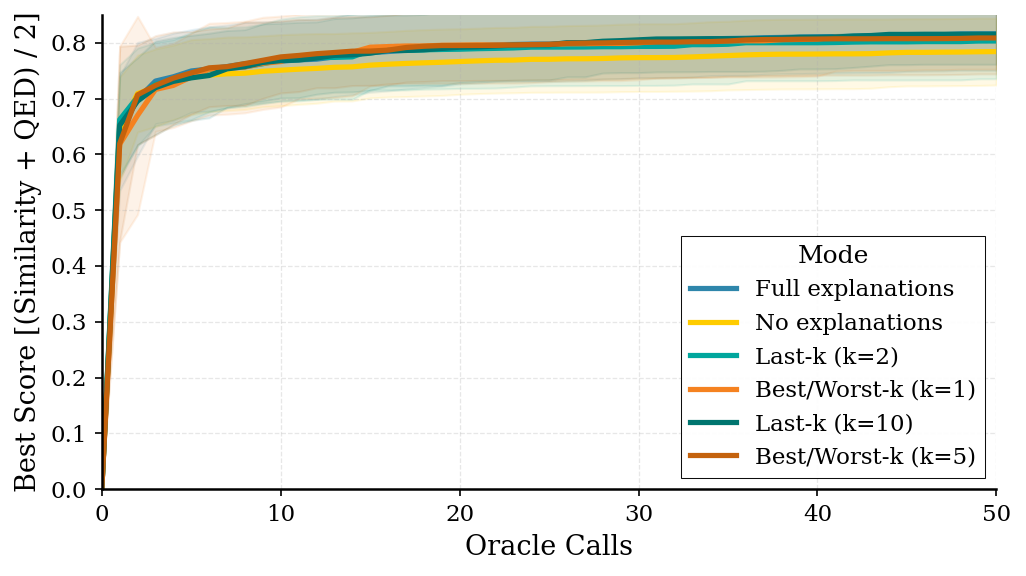

In [17]:
# Best-so-far per run; runs that ended early (success) keep their last value
prog = rows_df[rows_df['iteration'] <= MAX_ORACLE_CALLS].sort_values('iteration').copy()
prog['best_so_far'] = prog.groupby('run')['score'].cummax()
wide = (
    prog.pivot_table(index='iteration', columns='run', values='best_so_far')
    .reindex(range(0, MAX_ORACLE_CALLS + 1))
    .reindex(columns=runs_df['run'])
    .ffill()
    .fillna(0)  # baseline at oracle call 0 (no score yet)
)
long = wide.melt(ignore_index=False, var_name='run', value_name='best_so_far').reset_index()
long = long.merge(runs_df, on='run')

# average the runs of each molecule, so every molecule counts once in every mode
per_molecule = long.groupby(['mode', 'molecule', 'iteration'], as_index=False)['best_so_far'].mean()

plot_order = [m['label'] for m in modes if m['family'] == 'full'] + [m['label'] for m in modes if m['family'] == 'none'] + [m['label'] for m in modes if m['family'] not in ('full', 'none')]
palette = {m['label']: m['color'] for m in modes}

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
sns.lineplot(
    data=per_molecule, x='iteration', y='best_so_far', hue='mode',
    hue_order=plot_order, palette=palette,
    errorbar='sd', err_kws={'alpha': 0.1}, linewidth=2.5, ax=ax,
)
ax.set_xlabel('Oracle Calls', fontsize=13)
ax.set_ylabel('Best Score [(Similarity + QED) / 2]', fontsize=13)
ax.set_xlim(0, MAX_ORACLE_CALLS)
ax.set_ylim(0, 0.85)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
legend = ax.legend(title='Mode', frameon=True, fancybox=False, shadow=False, framealpha=0.95, edgecolor='black', loc='lower right')
legend.get_frame().set_linewidth(0.5)

plt.tight_layout()
plt.savefig('./figures/xai_history_modes_progression.pdf', format='pdf', bbox_inches='tight', dpi=300)
plt.show()